# Exploratory Check: Do Repeat Hospital Visits Increase Readmission?

During data preparation, I asked if patients with more hospital visits have a higher 30-day readmission rate. This question came from my experience in emergency medicine, where frequent attenders often return. This notebook tests that observation. It compares the readmission rate of patients with more visits with the average rate of the dataset.

The notebook uses two types of visit data:

1. **Encounters in the dataset.** A patient can have more than one encounter in the raw data. Part A counts these encounters.
2. **Visits in the year before the encounter.** The columns `number_inpatient`, `number_emergency` and `number_outpatient` give the number of visits in the year before the encounter. Part B uses these columns, because a model can use them at discharge.

**Important:** Part A shows a pattern, but a model must not use the total number of encounters. A later encounter can be the readmission. Thus, the total count contains information from the future. Part B has no such problem.

**Inputs**
- `Data/DataMainTable/diabetic_data.csv`: the raw data
- `Data/DataMainTable/IDS_mapping.csv`: the descriptions of the ID codes
- `Data/cleaned_diabetic_data.csv`: the output of `py/DataPrep/`

**How to run:** use Restart Kernel → Run All.

## 1. Setup
This cell imports the libraries and finds the repository root. It also makes the `Paper/figures` folder for saved charts.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from pathlib import Path
from scipy.stats import chi2_contingency, spearmanr
from sklearn.model_selection import train_test_split

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "ReadMe.md").exists())
RAW_PATH   = ROOT / "Data/DataMainTable/diabetic_data.csv"
MAP_PATH   = ROOT / "Data/DataMainTable/IDS_mapping.csv"
CLEAN_PATH = ROOT / "Data/cleaned_diabetic_data.csv"
FIG = ROOT / "Paper/figures"; FIG.mkdir(parents=True, exist_ok=True)

SEED = 42
TEAL = "#0D8A83"
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 40)
print("Repo root:", ROOT)

Repo root: C:\Users\JanAr\IdeaProjects\Data-Analytics-diabetes-readmission\Data-Analytics-diabetes-readmission


## 2. Helper functions
`read_ids_mapping` reads the three lookup tables in `IDS_mapping.csv`. `rate_table` calculates the readmission rate, the number of encounters and the ratio to the average rate for each group. `rate_plot` shows the rate for each group with a 95% confidence interval. The dashed line is the average rate.

In [2]:
def read_ids_mapping(path):
    tables, current, name = {}, [], None
    for line in Path(path).read_text().splitlines():
        if not line.strip(",").strip():
            if name: tables[name] = pd.DataFrame(current, columns=[name, "description"])
            current, name = [], None
        elif name is None:
            name = line.split(",")[0]
        else:
            code_, desc = line.split(",", 1)
            current.append((int(code_), desc.strip().strip('"')))
    if name: tables[name] = pd.DataFrame(current, columns=[name, "description"])
    return tables

def rate_table(data, col, target="readmitted_30d"):
    base = data[target].mean()
    t = data.groupby(col, observed=True)[target].agg(rate="mean", n="size")
    t = t[t["n"] > 0]
    t["ratio_to_average"] = (t["rate"] / base).round(2)
    t["rate"] = (t["rate"] * 100).round(1)
    return t.rename(columns={"rate": "rate_%"})

def rate_plot(data, col, title, xlabel, save=None, target="readmitted_30d"):
    base = data[target].mean()
    order = list(data[col].cat.categories) if hasattr(data[col], "cat") else sorted(data[col].unique())
    counts = data[col].value_counts()
    order = [o for o in order if counts.get(o, 0) > 0]      # hide empty groups
    plt.figure(figsize=(6.5, 3.6))
    ax = sns.barplot(data=data, x=col, y=target, order=order,
                     errorbar=("ci", 95), color=TEAL)
    ax.axhline(base, ls="--", c="grey", label=f"Average ({base:.1%})")
    ax.set_xticks(range(len(order)))
    ax.set_xticklabels([f"{o}\n(n={counts.get(o, 0):,})" for o in order], fontsize=9)
    ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=None))
    ax.set(title=title, xlabel=xlabel, ylabel="30-day readmission rate")
    ax.legend(loc="upper left")
    plt.tight_layout()
    if save: plt.savefig(FIG / save, dpi=200, bbox_inches="tight")
    plt.show()

def band(s, top):
    """Put counts into ordered groups 0, 1, ..., top-1, top+."""
    labels = [str(i) for i in range(top)] + [f"{top}+"]
    return pd.Categorical(np.where(s >= top, f"{top}+", s.astype(int).astype(str)),
                          categories=labels, ordered=True)

def fmt_p(p):
    return "< 1e-300" if p == 0 else f"{p:.1e}"

def chi2_test(data, col, target="readmitted_30d"):
    table = pd.crosstab(data[col], data[target])
    chi2, p, dof, _ = chi2_contingency(table)
    return chi2, p, dof

# Part A: Encounters in the dataset

## 3. Load the raw encounters
This cell loads all raw encounters. Only “?” is a missing value. The cell removes encounters that ended in death or discharge to a hospice, because these patients cannot be readmitted. The codes come from `IDS_mapping.csv`. The cell does not keep only the first stay, because Part A examines all encounters of each patient.

In [3]:
raw = pd.read_csv(RAW_PATH, na_values="?", keep_default_na=False, dtype={"payer_code": str})
dd = read_ids_mapping(MAP_PATH)["discharge_disposition_id"]
END_CODES = dd.loc[dd["description"].str.startswith(("Expired", "Hospice")),
                   "discharge_disposition_id"].tolist()

enc = raw[~raw["discharge_disposition_id"].isin(END_CODES)].copy()
enc["readmitted_30d"] = (enc["readmitted"] == "<30").astype(int)
AVG_ENC = enc["readmitted_30d"].mean()

print("Death and hospice codes:", END_CODES)
print(f"Encounters: {len(enc):,} from {enc['patient_nbr'].nunique():,} patients")
print(f"Average 30-day readmission rate (all encounters): {AVG_ENC:.1%}")

Death and hospice codes: [11, 13, 14, 19, 20, 21]
Encounters: 99,343 from 69,990 patients
Average 30-day readmission rate (all encounters): 11.4%


## 4. Number of encounters for each patient
This cell counts the encounters of each patient and shows the distribution. Most patients have one encounter. A small group of patients has many encounters.

In [4]:
enc = enc.sort_values("encounter_id")
enc["total_encounters"] = enc.groupby("patient_nbr")["encounter_id"].transform("size")
per_patient = enc.groupby("patient_nbr").size()

dist = band(per_patient, 6).value_counts().sort_index().loc[lambda s: s > 0].to_frame("patients")
dist["share_%"] = (dist["patients"] / dist["patients"].sum() * 100).round(1)
display(dist)

share_multi = enc.loc[enc["total_encounters"] > 1, "readmitted_30d"].sum() / enc["readmitted_30d"].sum()
print(f"Patients with more than 1 encounter: {(per_patient > 1).sum():,} "
      f"({(per_patient > 1).mean():.1%} of patients)")
print(f"Share of all 30-day readmissions from these patients: {share_multi:.1%}")

,patients,share_%
1,53649,76.7
2,10218,14.6
3,3233,4.6
4,1354,1.9
5,691,1.0
6+,845,1.2


Patients with more than 1 encounter: 16,341 (23.3% of patients)
Share of all 30-day readmissions from these patients: 79.8%


## 5. Readmission rate by total number of encounters
This cell compares the readmission rate of patients with 1, 2, 3 … encounters with the average rate.

**Do not use this result in a model.** The total number of encounters includes encounters after the current encounter. A 30-day readmission is itself a later encounter. Thus, patients with one encounter can have a readmission only if the readmission is outside this dataset. This makes the effect look larger than it is.

,rate_%,n,ratio_to_average
total_group,,,
1,4.3,53649,0.37
2,15.2,20436,1.34
3,19.4,9699,1.70
4,21.5,5416,1.89
5,24.3,3455,2.13
6+,30.4,6688,2.67


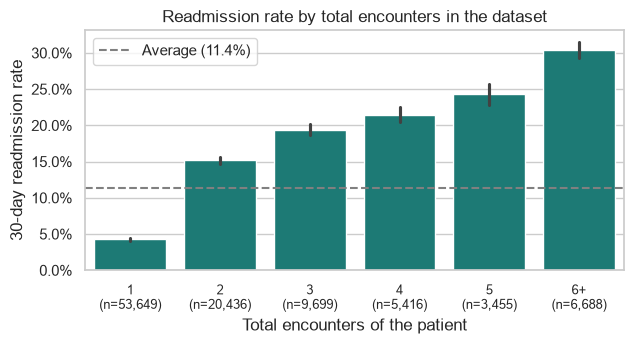

In [5]:
enc["total_group"] = band(enc["total_encounters"], 6)
display(rate_table(enc, "total_group"))
rate_plot(enc, "total_group",
          "Readmission rate by total encounters in the dataset",
          "Total encounters of the patient")

## 6. Readmission rate by earlier encounters in the dataset
This cell counts, for each encounter, the number of earlier encounters of the same patient in the dataset. This count uses only the past, so it has no information from the future.

**Assumption:** a higher `encounter_id` is a later encounter. The dataset documentation does not say this directly.

,rate_%,n,ratio_to_average
earlier_group,,,
0,9.0,69990,0.79
1,14.2,16341,1.24
2,17.4,6123,1.53
3,19.4,2890,1.71
4,21.5,1536,1.89
5+,30.7,2463,2.69


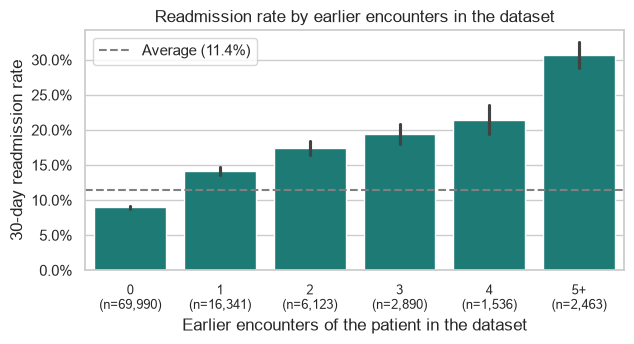

Chi-square = 1,996.1, dof = 5, p < 1e-300
Spearman rho = 0.128, p < 1e-300


In [6]:
enc["earlier_encounters"] = enc.groupby("patient_nbr").cumcount()
enc["earlier_group"] = band(enc["earlier_encounters"], 5)
display(rate_table(enc, "earlier_group"))
rate_plot(enc, "earlier_group",
          "Readmission rate by earlier encounters in the dataset",
          "Earlier encounters of the patient in the dataset",
          save="rate_earlier_encounters.png")

chi2, p, dof = chi2_test(enc, "earlier_group")
rho, p_rho = spearmanr(enc["earlier_encounters"], enc["readmitted_30d"])
print(f"Chi-square = {chi2:,.1f}, dof = {dof}, p {fmt_p(p)}")
print(f"Spearman rho = {rho:.3f}, p {fmt_p(p_rho)}")

**Finding (Part A):** The readmission rate increases with each earlier encounter in the dataset. Encounters with no earlier encounter have a rate of 9.0%, below the average of 11.4%. Encounters with 5 or more earlier encounters have a rate of 30.7%, 2.7 times the average. Only 23.3% of patients have more than one encounter, but these patients have 79.8% of all 30-day readmissions. The rate by total encounters (Section 5) shows a similar pattern, but it contains information from the future.

# Part B: Visits in the year before the encounter (model data)

## 7. Load the cleaned data and divide it
This cell loads the cleaned data (one encounter for each patient). It makes the same 80/20 split as `DataCheck.ipynb`, with the same random seed. Part B uses the training data only, so that the test data stays unseen for the model.

In [7]:
df = pd.read_csv(CLEAN_PATH)
df["readmitted_30d"] = (df["readmitted"] == "<30").astype(int)
train, test = train_test_split(df, test_size=0.2, stratify=df["readmitted_30d"], random_state=SEED)
train = train.copy()
AVG = train["readmitted_30d"].mean()

train["prior_visits"] = train[["number_inpatient", "number_emergency", "number_outpatient"]].sum(axis=1)
print(f"Training rows: {len(train):,}")
print(f"Average 30-day readmission rate (training data): {AVG:.1%}")
display(train[["number_inpatient", "number_emergency", "number_outpatient", "prior_visits"]]
        .describe().T.round(2))

Training rows: 55,989
Average 30-day readmission rate (training data): 9.0%


,count,mean,std,min,25%,50%,75%,max
number_inpatient,55989.0,0.18,0.60,0.0,0.0,0.0,0.0,12.0
number_emergency,55989.0,0.10,0.50,0.0,0.0,0.0,0.0,37.0
number_outpatient,55989.0,0.28,1.05,0.0,0.0,0.0,0.0,42.0
prior_visits,55989.0,0.56,1.41,0.0,0.0,0.0,1.0,42.0


## 8. Readmission rate by inpatient visits in the year before
This cell shows the readmission rate for 0, 1, 2, 3 and 4+ inpatient visits in the year before the encounter. Inpatient visits are earlier hospital admissions.

,rate_%,n,ratio_to_average
number_inpatient_group,,,
0,8.1,49424,0.91
1,13.1,4645,1.46
2,17.3,1201,1.93
3,23.5,370,2.62
4+,28.7,349,3.19


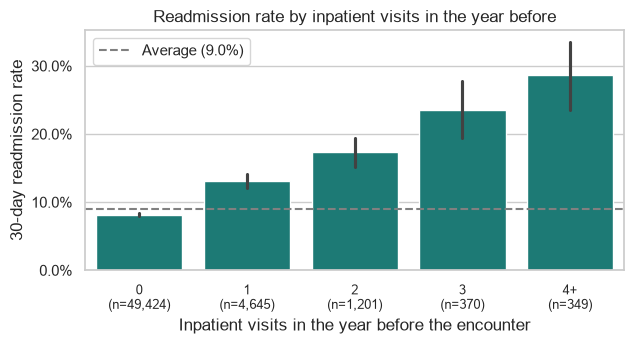

In [8]:
train["number_inpatient_group"] = band(train["number_inpatient"], 4)
display(rate_table(train, "number_inpatient_group"))
rate_plot(train, "number_inpatient_group",
          "Readmission rate by inpatient visits in the year before",
          "Inpatient visits in the year before the encounter",
          save="rate_inpatient.png")

## 9. Emergency, outpatient and all earlier visits
This cell shows the same rate for emergency visits, outpatient visits and the sum of all three visit types.

Emergency visits


,rate_%,n,ratio_to_average
number_emergency_group,,,
0,8.7,51930,0.97
1,11.2,3084,1.25
2,13.3,625,1.48
3,14.0,200,1.56
4+,22.0,150,2.45


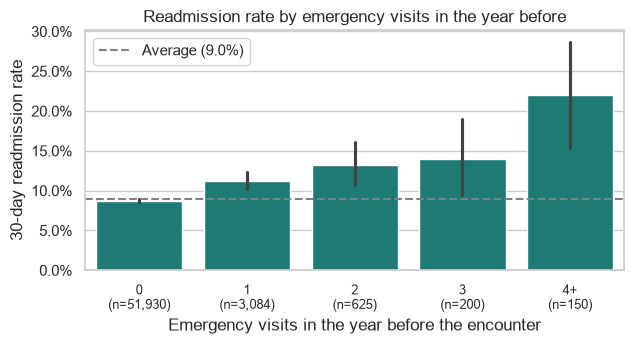

Outpatient visits


,rate_%,n,ratio_to_average
number_outpatient_group,,,
0,8.8,48694,0.98
1,10.3,3830,1.15
2,10.5,1560,1.17
3,8.8,894,0.98
4+,10.4,1011,1.16


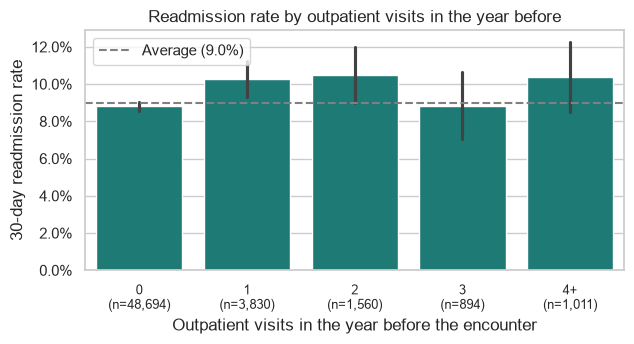

All visits


,rate_%,n,ratio_to_average
prior_visits_group,,,
0,7.9,41417,0.88
1,10.7,7638,1.19
2,12.2,3144,1.36
3,13.1,1667,1.46
4+,15.2,2123,1.69


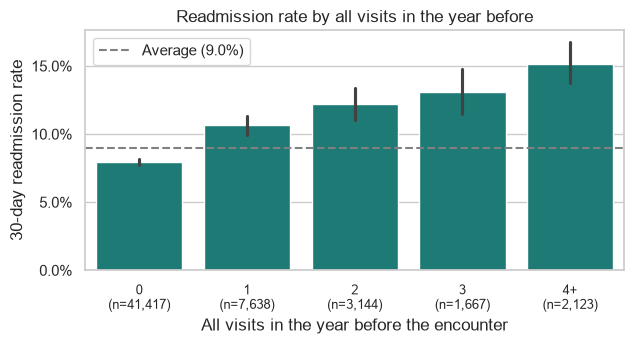

In [9]:
for col, label in [("number_emergency", "Emergency visits"),
                   ("number_outpatient", "Outpatient visits"),
                   ("prior_visits", "All visits")]:
    g = col + "_group"
    train[g] = band(train[col], 4)
    print(label)
    display(rate_table(train, g))
    rate_plot(train, g, f"Readmission rate by {label.lower()} in the year before",
              f"{label} in the year before the encounter")

## 10. Statistical tests
This cell tests if the readmission rate is different between the visit groups. The chi-square test compares the groups. The Spearman correlation shows if the rate increases with the number of visits. With 55,989 rows, small effects also have small p-values. Thus, the ratio to the average is more important than the p-value.

In [10]:
tests = []
for col in ["number_inpatient", "number_emergency", "number_outpatient", "prior_visits"]:
    chi2, p, dof = chi2_test(train, col + "_group")
    rho, p_rho = spearmanr(train[col], train["readmitted_30d"])
    tests.append({"feature": col, "chi2": round(chi2, 1), "dof": dof, "p_chi2": fmt_p(p),
                  "spearman_rho": round(rho, 3), "p_spearman": fmt_p(p_rho)})
display(pd.DataFrame(tests).set_index("feature"))

,chi2,dof,p_chi2,spearman_rho,p_spearman
feature,,,,,
number_inpatient,500.1,4,6.5e-107,0.083,2.7e-85
number_emergency,74.0,4,3.2e-15,0.031,3.6e-13
number_outpatient,16.8,4,2.1e-03,0.016,1.7e-04
prior_visits,253.6,4,1.1e-53,0.065,6.3e-53


## 11. Summary: more visits compared with the average
This cell compares patients with no earlier visits and patients with earlier visits with the average rate of the training data.

In [11]:
rows = []
for col, label in [("number_inpatient", "Inpatient"), ("number_emergency", "Emergency"),
                   ("number_outpatient", "Outpatient"), ("prior_visits", "All visits")]:
    for name, mask in [("0 visits", train[col] == 0), ("1+ visits", train[col] >= 1),
                       ("3+ visits", train[col] >= 3)]:
        r = train.loc[mask, "readmitted_30d"]
        rows.append({"visit type": label, "group": name, "n": len(r),
                     "rate_%": round(r.mean() * 100, 1),
                     "ratio_to_average": round(r.mean() / AVG, 2)})
summary = pd.DataFrame(rows).set_index(["visit type", "group"])
print(f"Average rate (training data): {AVG:.1%}")
display(summary)

Average rate (training data): 9.0%


n  rate_%  ratio_to_average
visit type group                                     
Inpatient  0 visits   49424     8.1              0.91
           1+ visits   6565    15.3              1.70
           3+ visits    719    26.0              2.90
Emergency  0 visits   51930     8.7              0.97
           1+ visits   4059    12.1              1.34
           3+ visits    350    17.4              1.94
Outpatient 0 visits   48694     8.8              0.98
           1+ visits   7295    10.2              1.13
           3+ visits   1905     9.7              1.08
All visits 0 visits   41417     7.9              0.88
           1+ visits  14572    11.9              1.33
           3+ visits   3790    14.2              1.59

## Findings

- **Earlier encounters in the dataset (Part A):** the readmission rate increases from 9.0% (no earlier encounter) to 30.7% (5 or more earlier encounters). The average is 11.4%.
- **Inpatient visits in the year before (Part B):** patients with no inpatient visit have a rate of 8.1% (0.91 × the average of 9.0%). Patients with 4 or more inpatient visits have a rate of 28.7% (3.19 × the average). This is the strongest visit feature (chi-square = 500.1, Spearman rho = 0.083).
- **Emergency visits:** the rate increases from 8.7% to 22.0% for 4 or more visits, but the effect is smaller than for inpatient visits (chi-square = 74.0).
- **Outpatient visits:** almost no effect. The rate stays between 8.8% and 10.5% in all groups.
- **Meaning for the model:** `number_inpatient` and `number_emergency` are strong candidate features. They are known at discharge, so they are permitted inputs. The total number of encounters in the dataset (Section 5) is not a permitted input, because it contains information from the future.
- **Limitation:** this analysis shows an association, not a cause. Patients with many visits are possibly more ill, and the illness can be the cause of both the visits and the readmission.

# AI Use Statement
I used Perplexity Computer, an AI assistant, to help make this notebook. The research question is my own. It came from my experience in emergency medicine during data preparation.

The AI wrote the first version of the code, the cell descriptions and the findings text. It also gave the statistical tests and the chart format. I examined the code, ran the notebook on my own computer and compared the output with the findings text. I am responsible for the content, the interpretation and the conclusions.

I did not use the AI to change the data. The data comes from my own data preparation scripts in `py/DataPrep/`.